<center><h1>Zheng_Yifei_HW5</h1></center>
<br>
<br>

Name: Yifei Zheng
<br>
Github Username: yyl-ff
<br>
USC ID: 8538054131

## 1. Decision Trees as Interpretable Models

Import packages

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import LabelEncoder

### (a) Obtain Data

Get the Accute Inamations Data Set

In [12]:
column_names = [
    "Temperature",
    "Nausea",
    "Lumbar_Pain",
    "Urine_Pushing",
    "Micturition_Pains",
    "Burning_Urethra",
    "Bladder_Inflammation",
    "Nephritis"
]

df = pd.read_csv(
    "acute+inflammations/diagnosis.data",
    sep="\t",
    header=None,
    names=column_names,
    encoding="utf-16",
    decimal=","
)

### (b) Build a decision tree

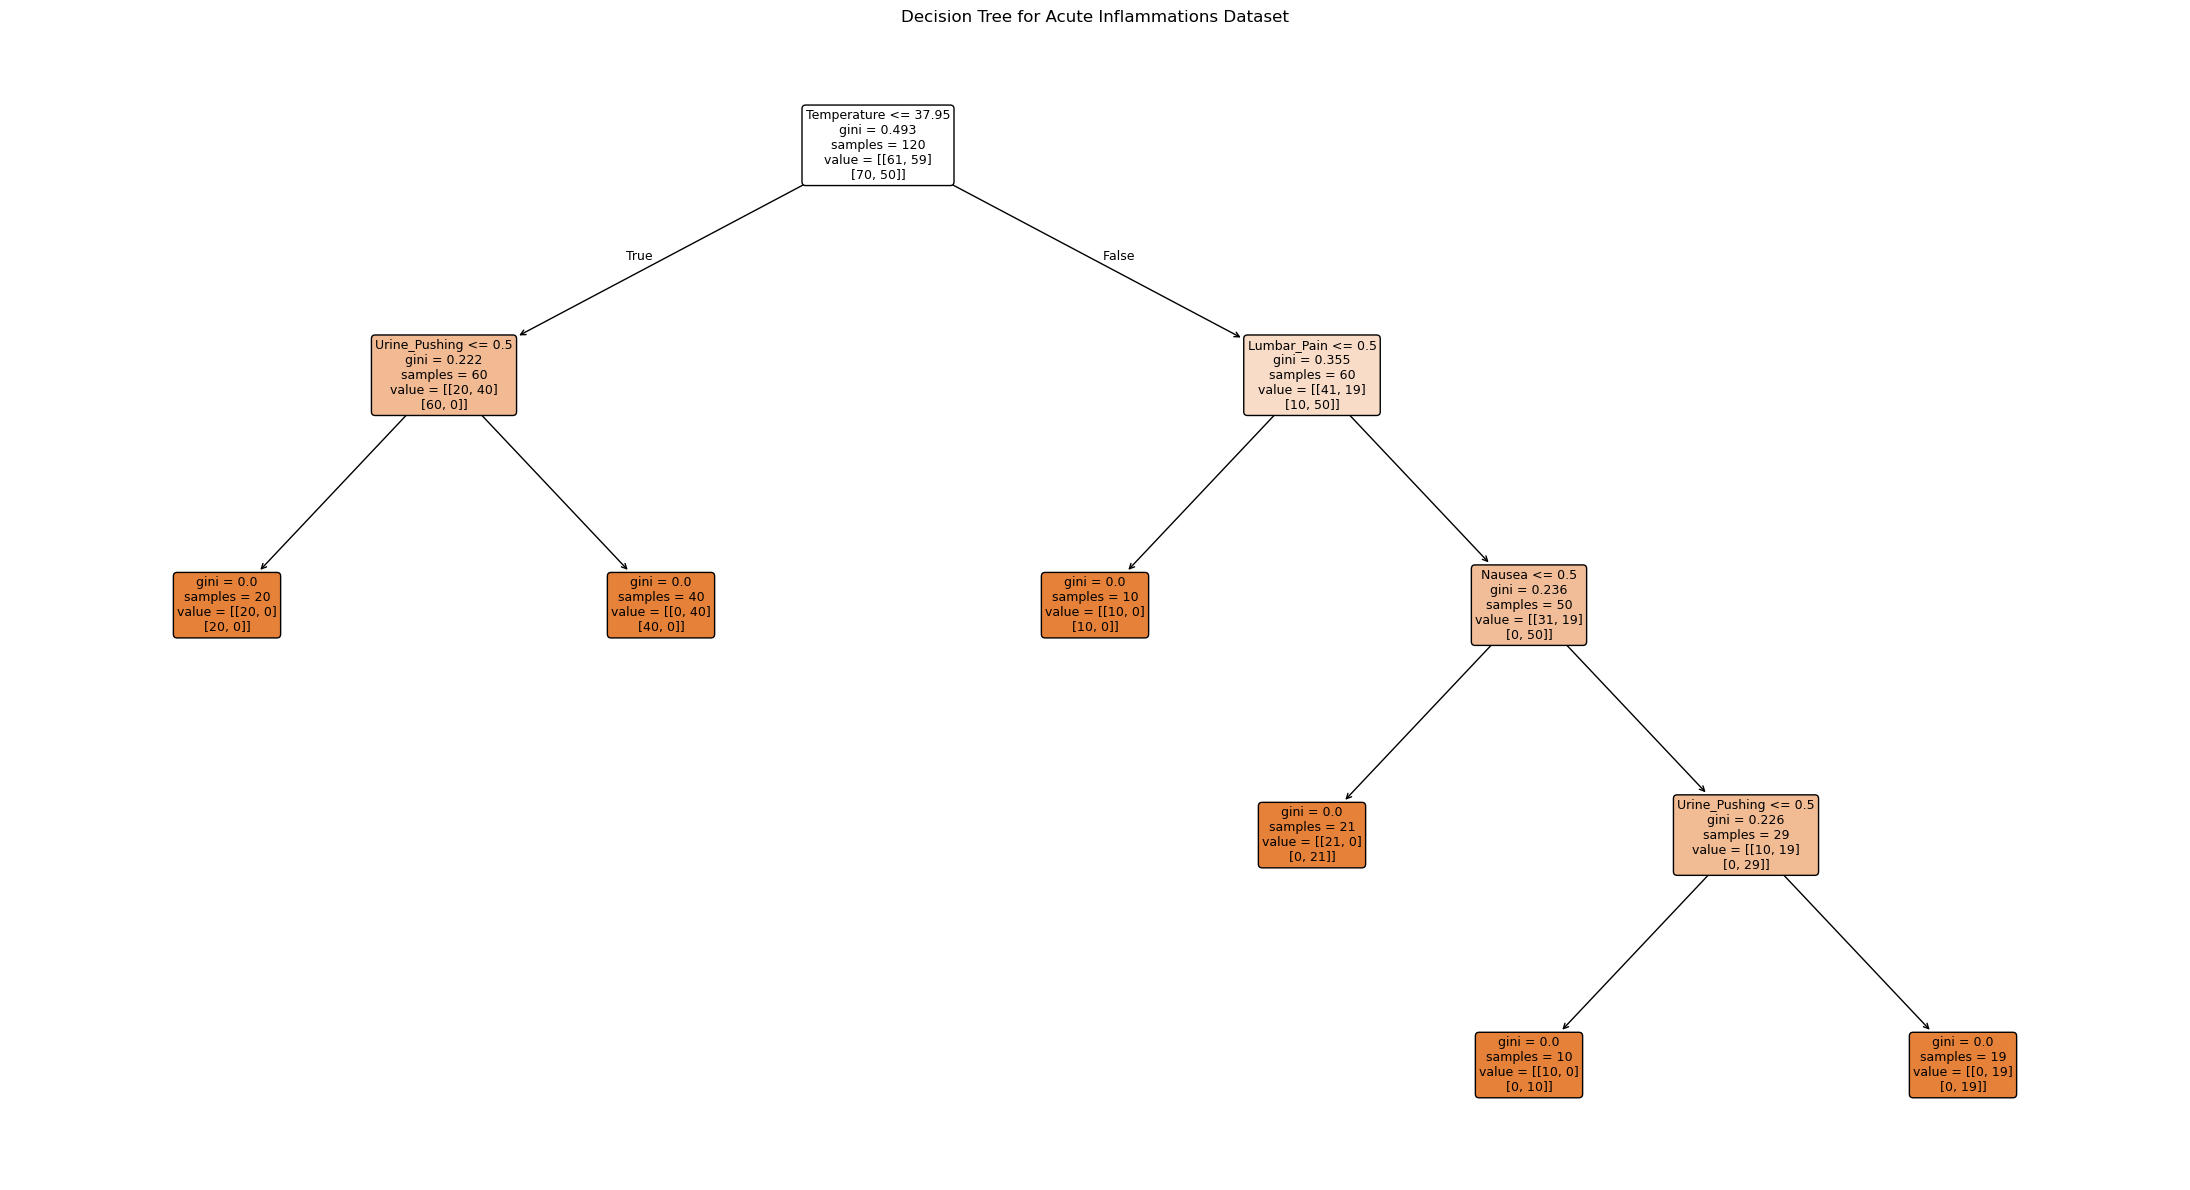

In [14]:
X = df.iloc[:, :6].copy()
y = df.iloc[:, 6:].copy()

binary_columns = X.columns[1:]

for column in binary_columns:
    X[column] = X[column].map({"yes": 1, "no": 0})

for column in y.columns:
    y[column] = y[column].map({"yes": 1, "no": 0})

decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X, y)

plt.figure(figsize=(22, 12))

plot_tree(
    decision_tree,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree for Acute Inflammations Dataset")
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [16]:
from sklearn.tree import _tree

def print_if_then_rules(model, feature_names, target_names):
    tree = model.tree_
    rules = []

    def build_rules(node, conditions):
        if tree.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree.feature[node]]
            threshold = tree.threshold[node]

            if feature == "Temperature":
                left_condition = f"{feature} <= {threshold:.2f}"
                right_condition = f"{feature} > {threshold:.2f}"

            else:
                left_condition = f"{feature} = no"
                right_condition = f"{feature} = yes"

            build_rules(
                tree.children_left[node],
                conditions + [left_condition]
            )

            build_rules(
                tree.children_right[node],
                conditions + [right_condition]
            )

        else:
            predicted_classes = np.argmax(
                tree.value[node],
                axis=1
            )

            predictions = []

            for target, predicted_class in zip(
                target_names,
                predicted_classes
            ):
                prediction = "yes" if predicted_class == 1 else "no"
                predictions.append(f"{target} = {prediction}")

            rules.append((conditions, predictions))

    build_rules(0, [])

    for rule_number, (conditions, predictions) in enumerate(rules, 1):
        print(f"Rule {rule_number}:")
        print("IF " + " AND ".join(conditions))
        print("THEN " + " AND ".join(predictions))
        print()


print_if_then_rules(
    decision_tree,
    list(X.columns),
    list(y.columns)
)

Rule 1:
IF Temperature <= 37.95 AND Urine_Pushing = no
THEN Bladder_Inflammation = no AND Nephritis = no

Rule 2:
IF Temperature <= 37.95 AND Urine_Pushing = yes
THEN Bladder_Inflammation = yes AND Nephritis = no

Rule 3:
IF Temperature > 37.95 AND Lumbar_Pain = no
THEN Bladder_Inflammation = no AND Nephritis = no

Rule 4:
IF Temperature > 37.95 AND Lumbar_Pain = yes AND Nausea = no
THEN Bladder_Inflammation = no AND Nephritis = yes

Rule 5:
IF Temperature > 37.95 AND Lumbar_Pain = yes AND Nausea = yes AND Urine_Pushing = no
THEN Bladder_Inflammation = no AND Nephritis = yes

Rule 6:
IF Temperature > 37.95 AND Lumbar_Pain = yes AND Nausea = yes AND Urine_Pushing = yes
THEN Bladder_Inflammation = yes AND Nephritis = yes



### (d) Cost-Complexity Pruning

Best ccp_alpha: 0.000000
Best cross-validation accuracy: 1.0000


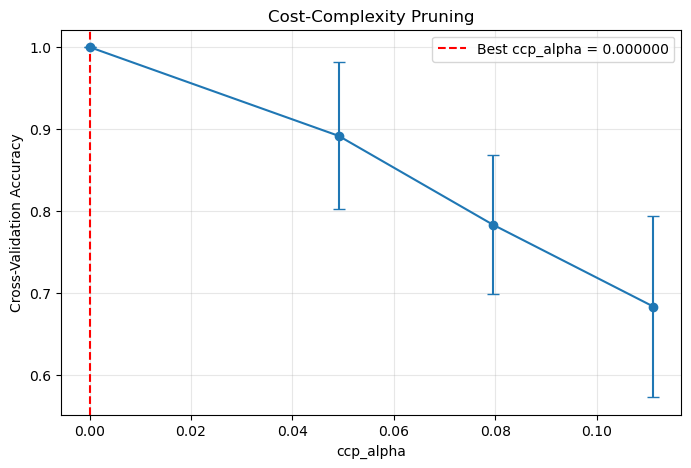

Number of nodes: 11
Number of leaves: 6
Tree depth: 4
Training accuracy: 1.0000


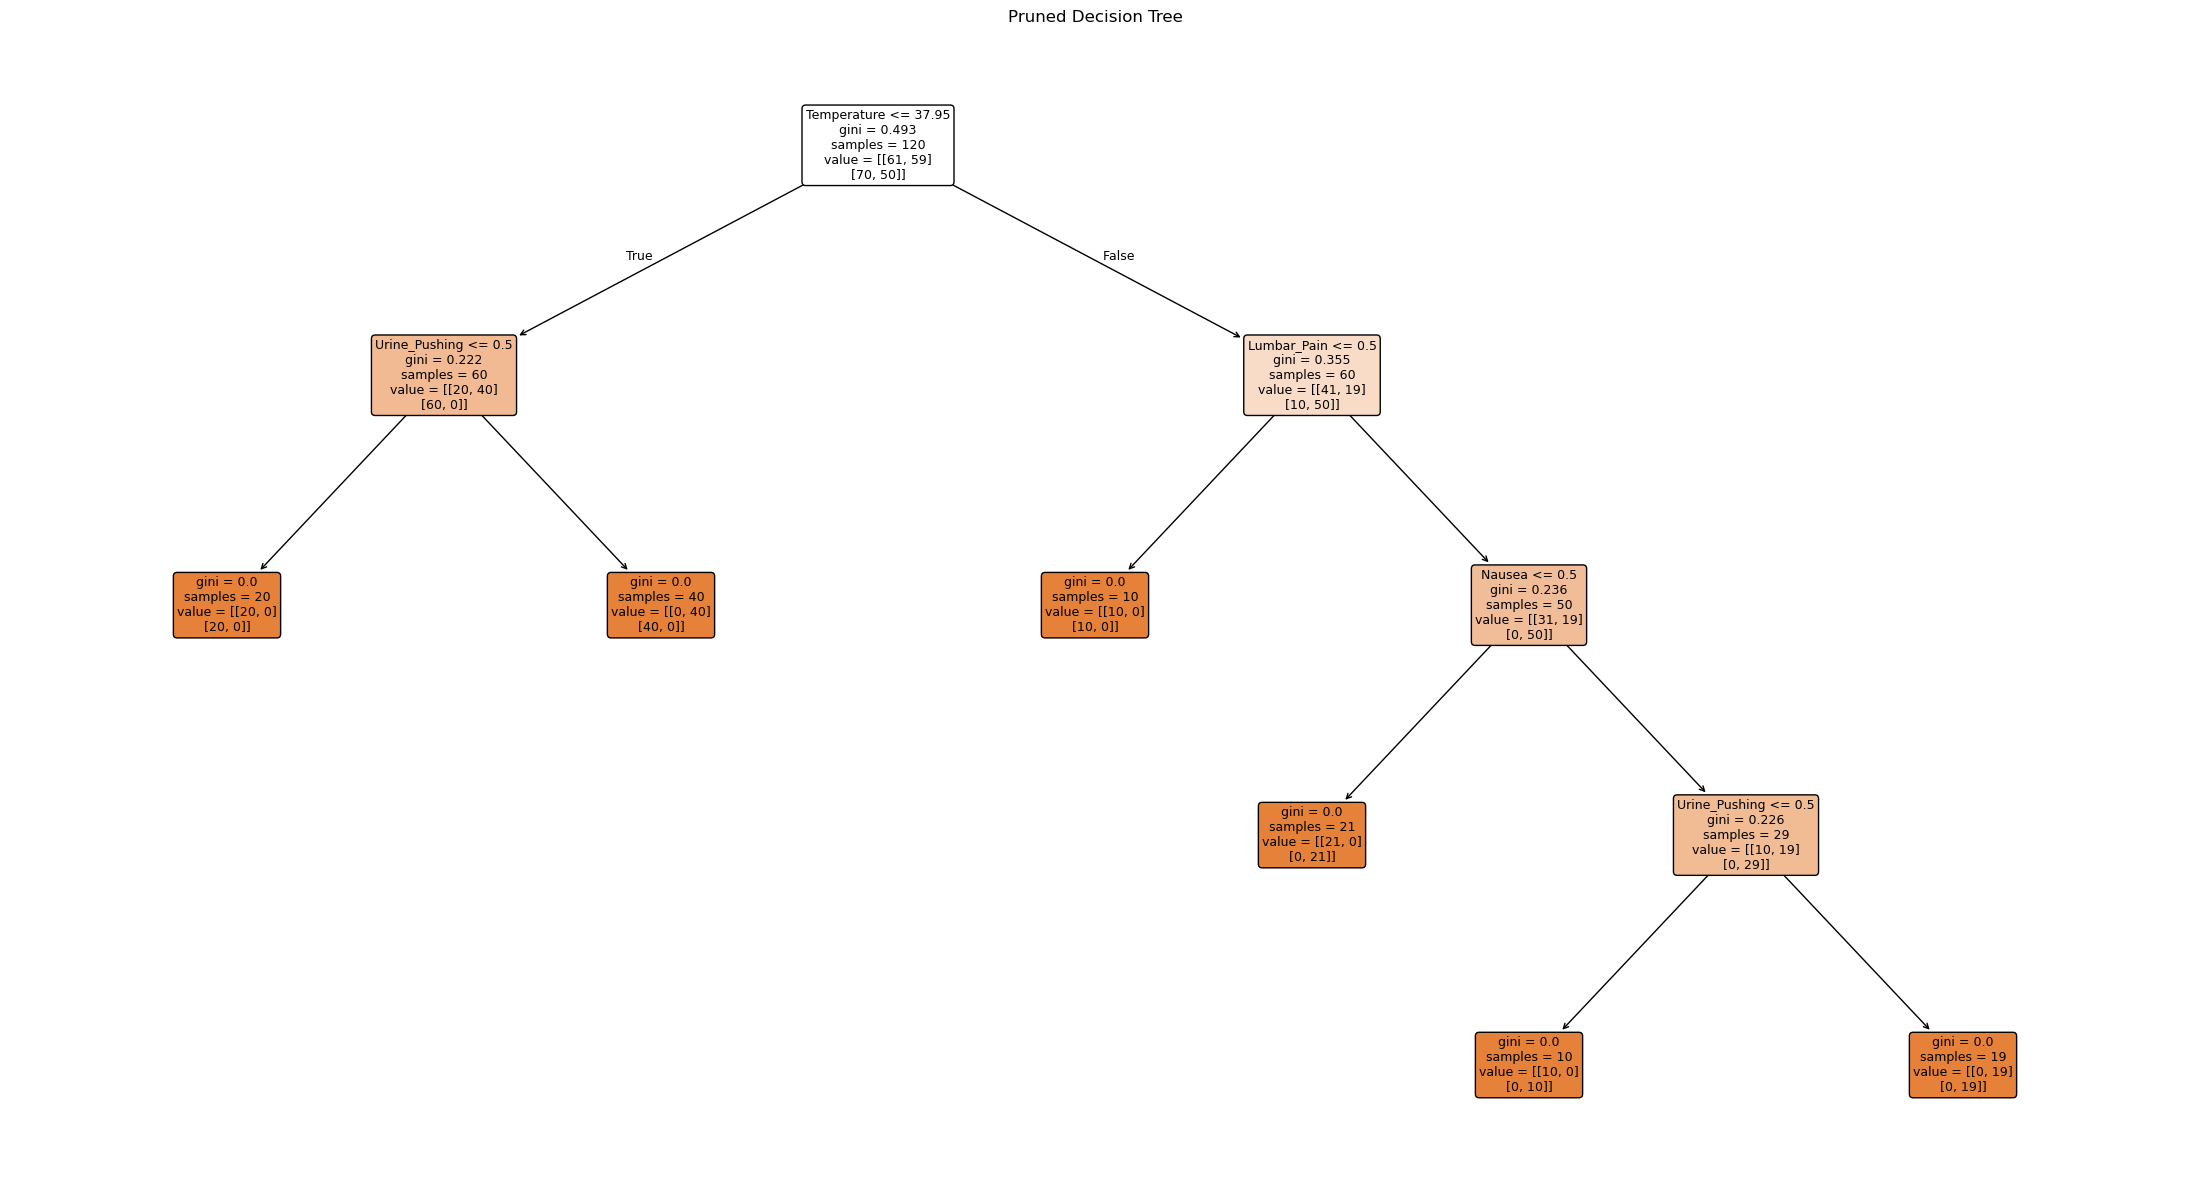

In [23]:
from sklearn.model_selection import KFold, cross_val_score

pruning_path = decision_tree.cost_complexity_pruning_path(X, y)
ccp_alphas = np.unique(pruning_path.ccp_alphas[:-1])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

mean_cv_scores = []
std_cv_scores = []

for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )

    scores = cross_val_score(
        tree,
        X,
        y,
        cv=cv,
        scoring="accuracy"
    )

    mean_cv_scores.append(scores.mean())
    std_cv_scores.append(scores.std())

mean_cv_scores = np.array(mean_cv_scores)
std_cv_scores = np.array(std_cv_scores)

best_score = mean_cv_scores.max()
best_indices = np.where(
    np.isclose(mean_cv_scores, best_score)
)[0]

best_index = best_indices[-1]
best_alpha = ccp_alphas[best_index]

print(f"Best ccp_alpha: {best_alpha:.6f}")
print(f"Best cross-validation accuracy: {best_score:.4f}")

plt.figure(figsize=(8, 5))

plt.errorbar(
    ccp_alphas,
    mean_cv_scores,
    yerr=std_cv_scores,
    marker="o",
    capsize=4
)

plt.axvline(
    best_alpha,
    color="red",
    linestyle="--",
    label=f"Best ccp_alpha = {best_alpha:.6f}"
)

plt.xlabel("ccp_alpha")
plt.ylabel("Cross-Validation Accuracy")
plt.title("Cost-Complexity Pruning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=best_alpha
)

pruned_tree.fit(X, y)

print("Number of nodes:", pruned_tree.tree_.node_count)
print("Number of leaves:", pruned_tree.tree_.n_leaves)
print("Tree depth:", pruned_tree.tree_.max_depth)
print(f"Training accuracy: {pruned_tree.score(X, y):.4f}")

plt.figure(figsize=(22, 12))

plot_tree(
    pruned_tree,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Pruned Decision Tree")
plt.tight_layout()
plt.show()

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [35]:
import re

with open(
    "communities+and+crime/communities.names",
    "r",
    encoding="latin-1"
) as file:
    names_text = file.read()

column_names = re.findall(
    r"^@attribute\s+(\S+)",
    names_text,
    flags=re.MULTILINE
)

communities_df = pd.read_csv(
    "communities+and+crime/communities.data",
    header=None,
    names=column_names,
    na_values="?"
)

train_data = communities_df.iloc[:1495].copy()
test_data = communities_df.iloc[1495:].copy()

print("Complete dataset shape:", communities_df.shape)
print("Training set shape:", train_data.shape)
print("Testing set shape:", test_data.shape)

print("\nTotal missing values:", communities_df.isnull().sum().sum())

Complete dataset shape: (1994, 128)
Training set shape: (1495, 128)
Testing set shape: (499, 128)

Total missing values: 39202


### (b) Missing values

In [37]:
from sklearn.impute import SimpleImputer

non_predictive_columns = [
    "state",
    "county",
    "community",
    "communityname",
    "fold"
]

target_column = "ViolentCrimesPerPop"

train_clean = train_data.drop(columns=non_predictive_columns).copy()
test_clean = test_data.drop(columns=non_predictive_columns).copy()

X_train_raw = train_clean.drop(columns=target_column)
y_train = train_clean[target_column].copy()
X_test_raw = test_clean.drop(columns=target_column)
y_test = test_clean[target_column].copy()

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

### (c) Plot a correlation matrix

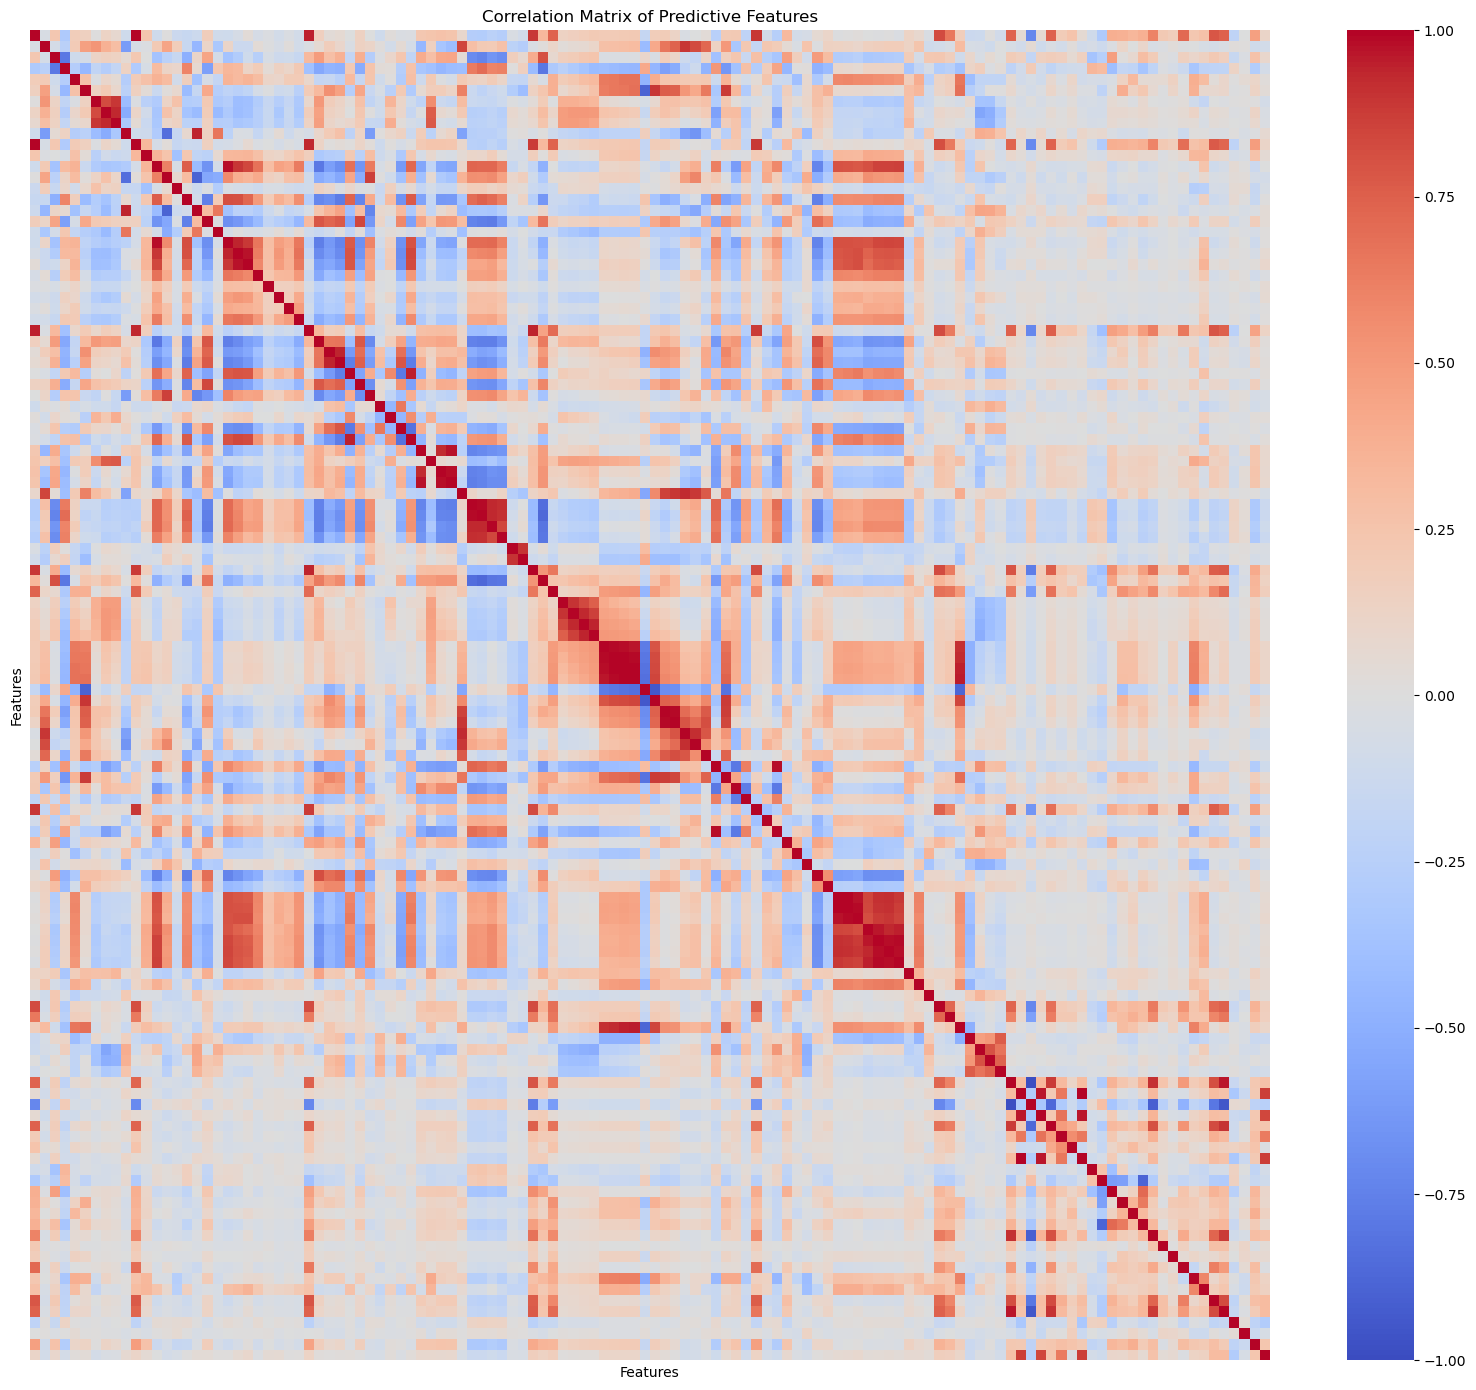

In [39]:
import seaborn as sns

X_complete = pd.concat(
    [X_train, X_test]
).sort_index()

correlation_matrix = X_complete.corr()

plt.figure(figsize=(16, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of Predictive Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [41]:
feature_means = X_complete.mean()
feature_standard_deviations = X_complete.std(ddof=1)

cv_values = feature_standard_deviations / feature_means

cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Standard Deviation": feature_standard_deviations,
    "CV": cv_values
}).sort_values(
    by="CV",
    ascending=False
)

display(cv_table)

,Mean,Standard Deviation,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
...,...,...,...
NumKindsDrugsSeiz,0.567768,0.081320,0.143227
RacialMatchCommPol,0.723506,0.091814,0.126902
LemasPctPolicOnPatr,0.750176,0.088376,0.117807
PctPolicWhite,0.763114,0.089838,0.117726


### (e) Scatter plots and box plots for highest CV features

,Mean,Standard Deviation,CV
PctPolicAsian,0.018375,0.100105,5.447835
NumStreet,0.022778,0.100400,4.407702
NumInShelters,0.029438,0.102607,3.485481
NumIlleg,0.036294,0.108671,2.994196
NumImmig,0.030060,0.087189,2.900497
LemasPctOfficDrugUn,0.094052,0.240328,2.555266
NumUnderPov,0.055507,0.127941,2.304970
population,0.057593,0.126906,2.203503
LemasSwornFT,0.027944,0.058143,2.080712
numbUrban,0.064072,0.128256,2.001744


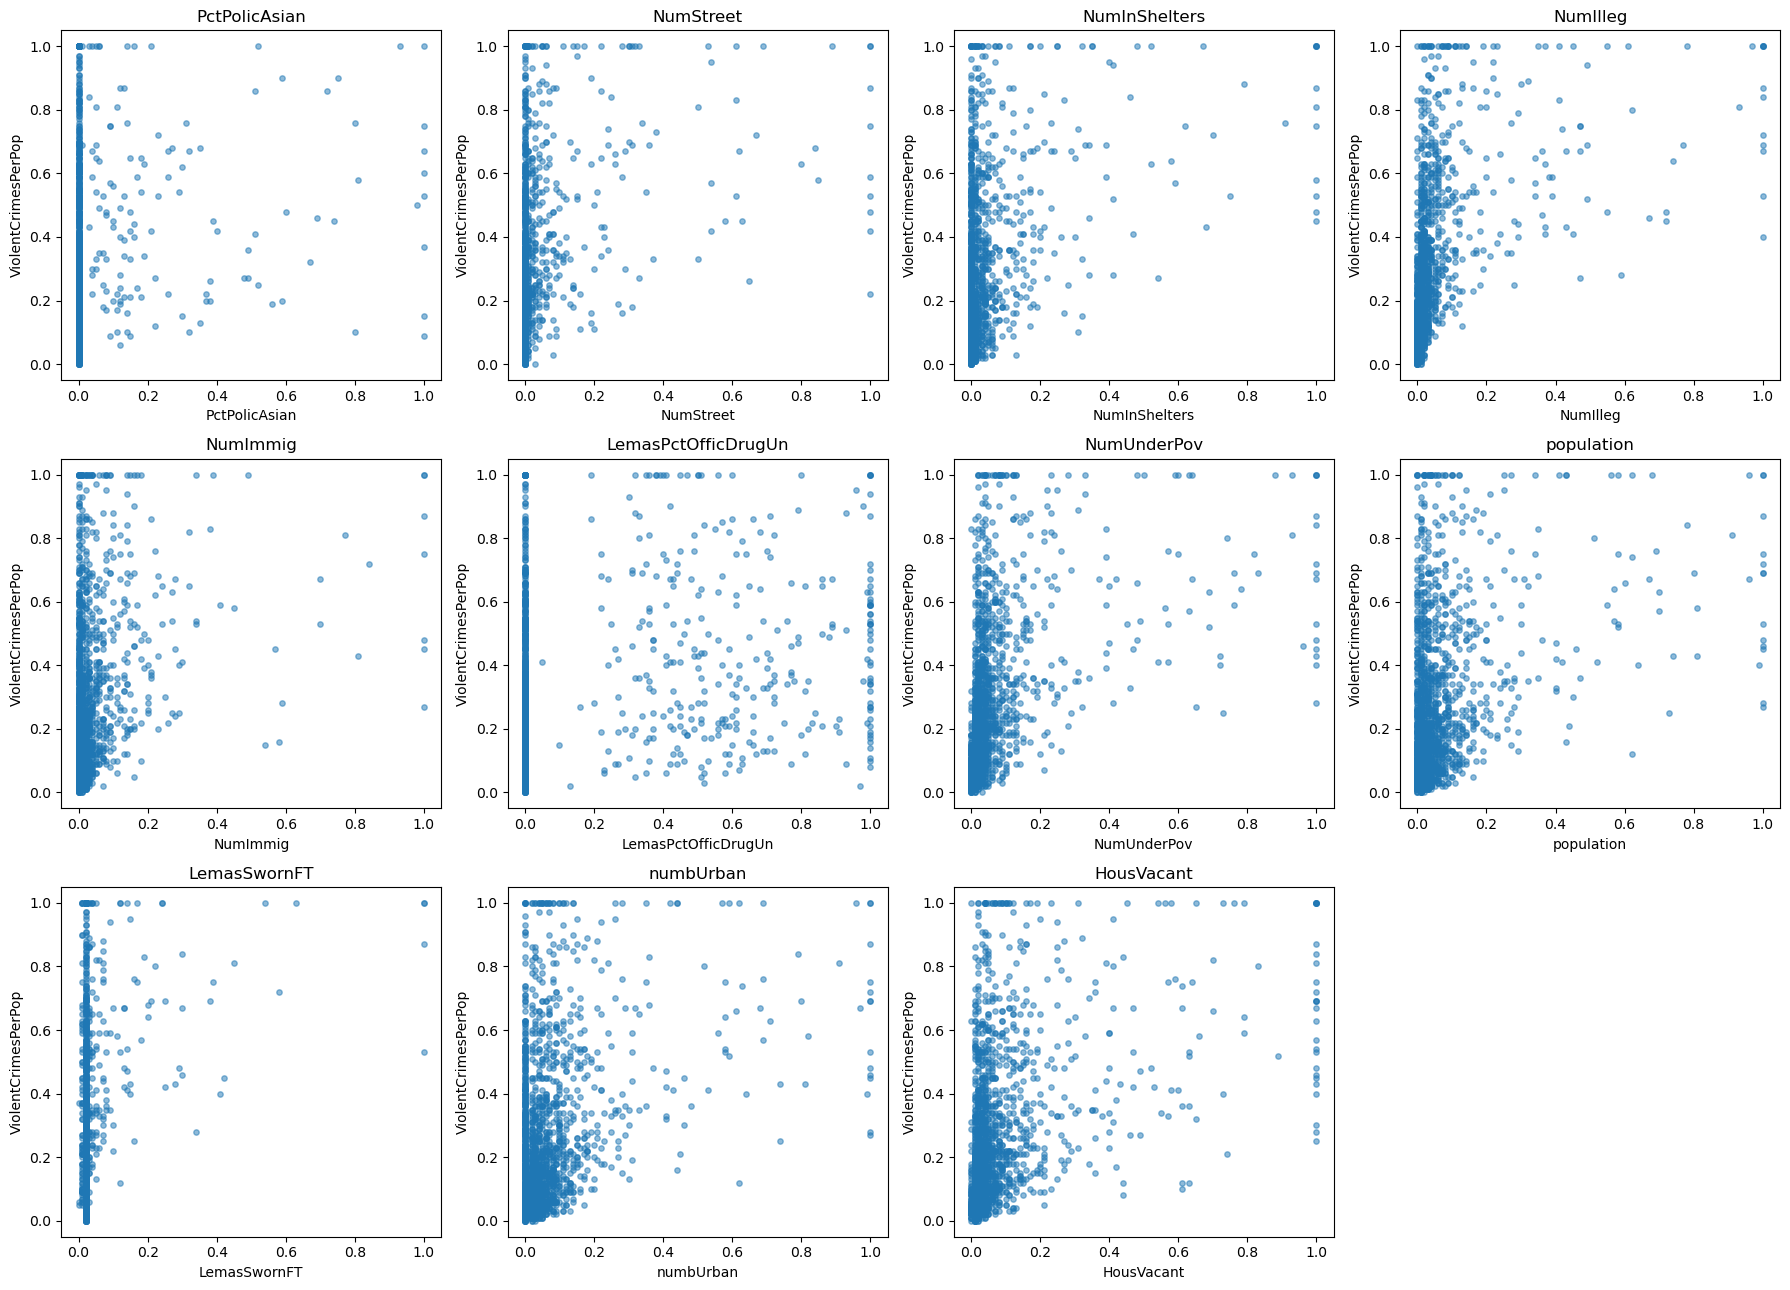

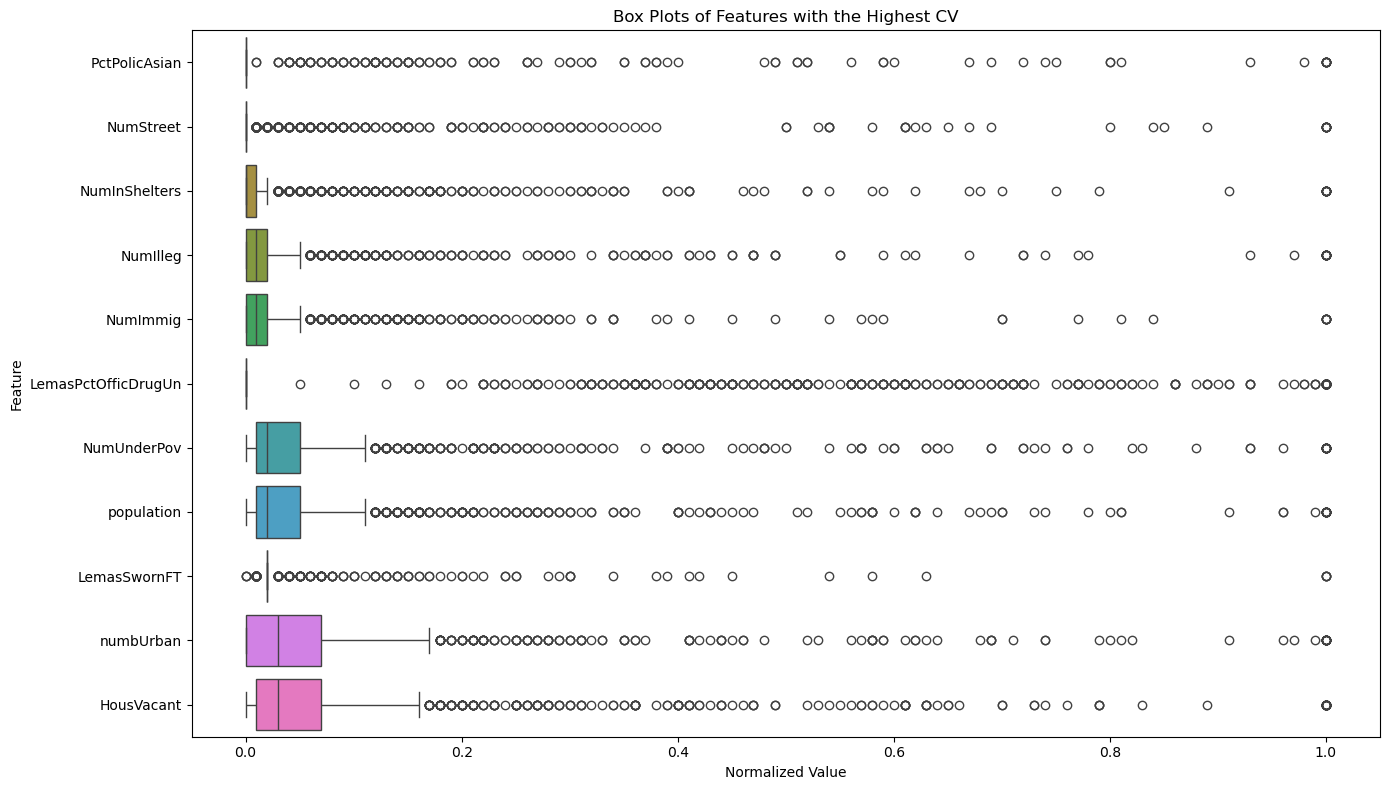

In [45]:
number_of_selected_features = int(np.floor(np.sqrt(128)))
selected_features = cv_table.head(number_of_selected_features).index.tolist()

display(cv_table.loc[selected_features])

y_complete = pd.concat(
    [y_train, y_test]
).sort_index()

fig, axes = plt.subplots(
    3,
    4,
    figsize=(18, 13)
)

axes = axes.flatten()

for index, feature in enumerate(selected_features):
    axes[index].scatter(
        X_complete[feature],
        y_complete,
        alpha=0.5,
        s=15
    )

    axes[index].set_title(feature)
    axes[index].set_xlabel(feature)
    axes[index].set_ylabel("ViolentCrimesPerPop")

for index in range(
    len(selected_features),
    len(axes)
):
    fig.delaxes(axes[index])

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=X_complete[selected_features],
    orient="h"
)

plt.title("Box Plots of Features with the Highest CV")
plt.xlabel("Normalized Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

The scatter plots may show possible relationships between the selected features and the response. However, the plots alone are not enough to determine whether these features are statistically significant. Formal statistical tests or regression analysis are needed to evaluate their significance.

### (f) Fit a linear model

In [50]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)
linear_test_error = mean_squared_error(
    y_test,
    linear_predictions
)

print(
    f"Linear Regression Test MSE: "
    f"{linear_test_error:.6f}"
)

Linear Regression Test MSE: 0.017966


### (g) Fit a ridge regression model

In [57]:
from sklearn.linear_model import RidgeCV

ridge_lambdas = np.logspace(-4, 4, 100)

ridge_model = RidgeCV(
    alphas=ridge_lambdas,
    scoring="neg_mean_squared_error"
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

ridge_test_error = mean_squared_error(y_test, ridge_predictions)

print(
    f"Best Ridge Lambda: "
    f"{ridge_model.alpha_:.6f}"
)

print(
    f"Ridge Regression Test MSE: "
    f"{ridge_test_error:.6f}"
)

Best Ridge Lambda: 2.310130
Ridge Regression Test MSE: 0.017516


### (h) Fit a LASSO model

In [59]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

lasso_model = LassoCV(
    cv=10,
    random_state=42,
    max_iter=100000,
    n_jobs=-1
)

lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_test)

lasso_test_error = mean_squared_error(y_test, lasso_predictions)

lasso_selected_variables = pd.DataFrame({
    "Variable": X_train.columns[lasso_model.coef_ != 0],
    "Coefficient": lasso_model.coef_[lasso_model.coef_ != 0]
})

print(
    f"Best LASSO Lambda: "
    f"{lasso_model.alpha_:.6f}"
)

print(
    f"LASSO Test MSE: "
    f"{lasso_test_error:.6f}"
)

print(
    f"Number of Selected Variables: "
    f"{len(lasso_selected_variables)}"
)

display(lasso_selected_variables)

scaler = StandardScaler()

X_train_standardized = scaler.fit_transform(X_train)

X_test_standardized = scaler.transform(X_test)

standardized_lasso_model = LassoCV(
    cv=10,
    random_state=42,
    max_iter=100000,
    n_jobs=-1
)

standardized_lasso_model.fit(X_train_standardized,y_train)

standardized_lasso_predictions = (
    standardized_lasso_model.predict(
        X_test_standardized
    )
)

standardized_lasso_test_error = (
    mean_squared_error(
        y_test,
        standardized_lasso_predictions
    )
)

standardized_selected_variables = pd.DataFrame({
    "Variable": X_train.columns[standardized_lasso_model.coef_ != 0],
    "Coefficient": standardized_lasso_model.coef_[standardized_lasso_model.coef_ != 0]
})

print(
    f"Best Standardized LASSO Lambda: "
    f"{standardized_lasso_model.alpha_:.6f}"
)

print(
    f"Standardized LASSO Test MSE: "
    f"{standardized_lasso_test_error:.6f}"
)

print(
    f"Number of Selected Variables: "
    f"{len(standardized_selected_variables)}"
)

display(standardized_selected_variables)

Best LASSO Lambda: 0.000108
LASSO Test MSE: 0.017646
Number of Selected Variables: 73


,Variable,Coefficient
0,racepctblack,0.268450
1,racePctAsian,-0.016237
2,agePct12t21,0.070303
3,agePct12t29,-0.277586
4,pctUrban,0.041006
...,...,...
68,PopDens,0.012319
69,PctUsePubTrans,-0.045225
70,PolicCars,0.023708
71,LemasPctPolicOnPatr,0.015134


Best Standardized LASSO Lambda: 0.000664
Standardized LASSO Test MSE: 0.017712
Number of Selected Variables: 75


,Variable,Coefficient
0,racepctblack,0.067904
1,racePctAsian,-0.001658
2,agePct12t21,0.011868
3,agePct12t29,-0.041974
4,pctUrban,0.017005
...,...,...
70,PopDens,0.003463
71,PctUsePubTrans,-0.009526
72,PolicCars,0.007476
73,LemasPctPolicOnPatr,0.001745


The LASSO model without standardization selected 73 variables and had a test MSE of 0.017646. The standardized LASSO model selected 75 variables and had a test MSE of 0.017712. The model without standardization performed slightly better because it had a lower test error. The difference is very small, which is reasonable because the features in this dataset were already normalized.

### (i) Fit a PCR model

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV

pcr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("linear_regression", LinearRegression())
])

pcr_parameters = {
    "pca__n_components": np.arange(1, X_train.shape[1] + 1)
}

pcr_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid=pcr_parameters,
    scoring="neg_mean_squared_error",
    cv=pcr_cv,
    n_jobs=-1
)

pcr_search.fit(X_train, y_train)
pcr_predictions = pcr_search.predict(X_test)
pcr_test_error = mean_squared_error(y_test, pcr_predictions)
best_number_of_components = (pcr_search.best_params_["pca__n_components"])

print(
    f"Best Number of Principal Components: "
    f"{best_number_of_components}"
)

print(
    f"PCR Test MSE: "
    f"{pcr_test_error:.6f}"
)

### (j) Fit a boosting tree

In [69]:
from xgboost import XGBRegressor

xgboost_model = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

alpha_values = np.concatenate([
    [0],
    np.logspace(-4, 1, 12)
])

xgboost_parameters = {"reg_alpha": alpha_values}

xgboost_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgboost_search = GridSearchCV(
    estimator=xgboost_model,
    param_grid=xgboost_parameters,
    scoring="neg_mean_squared_error",
    cv=xgboost_cv,
    n_jobs=-1
)

xgboost_search.fit(X_train, y_train)
xgboost_predictions = xgboost_search.predict(X_test)
xgboost_test_error = mean_squared_error(y_test, xgboost_predictions)
best_alpha = xgboost_search.best_params_["reg_alpha"]

print(
    f"Best XGBoost Alpha: "
    f"{best_alpha:.6f}"
)

print(
    f"XGBoost Test MSE: "
    f"{xgboost_test_error:.6f}"
)

Best XGBoost Alpha: 0.432876
XGBoost Test MSE: 0.015999
